# Diagnosing the ST-GNN advantage (Colab)

Uses original labels and the already audited Test 2 checkpoints. It compares the same flows for ST-GNN, Static GNN, and Edge GRU without assigning attack stages, tactics, or IPs. It also performs an **exploratory intervention**: resetting ST-GNN memory before every window without retraining. This tests checkpoint sensitivity to history, but does not establish a general causal contribution. Existing artifacts are not modified.


In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('torch_geometric') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torch_geometric'], check=True)
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = Path('/content/drive/MyDrive/nids-mitre')
RESULTS = DRIVE_ROOT / 'results_earlystopping'
GRAPH_ROOT = DRIVE_ROOT / 'dataset_processed_thu0103'
CLONE_DIR = Path('/content/temporalgnn-nids-mechanism')
BRANCH = 'feat/fair-comparison-experiments'
EXPECTED_COMMIT = '2262b53d155f9e8cf5221516f47e4170e6cd0d6e'
assert RESULTS.is_dir() and (GRAPH_ROOT / 'test2').is_dir()
if not CLONE_DIR.exists():
    subprocess.run(['git', 'clone', '--depth', '1', '--branch', BRANCH,
                    'https://github.com/tatipar/temporalgnn-nids.git', str(CLONE_DIR)], check=True)
subprocess.run(
    ['git', '-C', str(CLONE_DIR), 'fetch', '--depth', '1', 'origin', EXPECTED_COMMIT],
    check=True,
)
subprocess.run(
    ['git', '-C', str(CLONE_DIR), 'checkout', '--detach', EXPECTED_COMMIT],
    check=True,
)
commit = subprocess.check_output(['git', '-C', str(CLONE_DIR), 'rev-parse', 'HEAD'], text=True).strip()
assert commit == EXPECTED_COMMIT, f'Code commit changed: {commit}; expected {EXPECTED_COMMIT}'
sys.path.insert(0, str(CLONE_DIR / 'code/python'))
print('Pinned code:', commit)


Mounted at /content/drive
Pinned code: 2262b53d155f9e8cf5221516f47e4170e6cd0d6e


In [2]:
import gc, json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import torch
from torch_geometric.loader import DataLoader
from sklearn.metrics import average_precision_score
from IPython.display import display
from utils.datasets import NF_IDS_Dataset
from utils.models import ST_GNN_Identity, StaticGNN_Identity, EdgeGRU_Baseline_NoX
from utils.metrics import calculate_metrics_gnn

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PARAMS = dict(node_dim=16, edge_dim=32, hidden_dim=32, dropout=0.2,
              output_bias_init=-2.9968)
SPECS = {
    'ST-GNN': ('ST_GNN_BiasOn_robust_Identity_clone', ST_GNN_Identity, 42, True),
    'Static GNN': ('StaticGNN_BiasOn_robust_Identity', StaticGNN_Identity, 42, False),
    'Edge GRU': ('EdgeGRU_NoX_BiasOn', EdgeGRU_Baseline_NoX, 99, True),
}
DATASET = NF_IDS_Dataset(root_dir=str(GRAPH_ROOT), split='test2')
assert len(DATASET) == 2822, f'Expected 2,822 graphs; found {len(DATASET)}'
print('Device:', DEVICE, '| graph files:', len(DATASET))

def artifact(name):
    exp, cls, expected_seed, temporal = SPECS[name]
    old_path = RESULTS / 'test2_results' / f'test2_metrics_{exp}.csv'
    old = pd.read_csv(old_path)
    assert len(old) == 1 and int(old.iloc[0]['seed']) == expected_seed
    old = old.iloc[0]
    run_id = str(old['run_id'])
    hits = list((RESULTS / 'saved_models' / exp).glob(f'{run_id}_*.pth'))
    assert len(hits) == 1, f'Ambiguous checkpoint for {run_id}: {hits}'
    with np.load(RESULTS / 'logs' / exp / f'thresholds_{exp}.npz') as ths:
        th = float(ths[f'seed_{expected_seed}'])
    return dict(name=name, experiment=exp, cls=cls, temporal=temporal,
                seed=expected_seed, run_id=run_id, checkpoint=hits[0],
                threshold=th, old=old)

ARTIFACTS = {name: artifact(name) for name in SPECS}
display(pd.DataFrame([
    {k: v for k, v in a.items() if k in ('name','experiment','seed','run_id','threshold')}
    for a in ARTIFACTS.values()
]))


Device: cpu | graph files: 2822


,name,experiment,seed,run_id,threshold
0,ST-GNN,ST_GNN_BiasOn_robust_Identity_clone,42,ST_GNN_BiasOn_robust_Identity_clone_seed42_202...,0.203219
1,Static GNN,StaticGNN_BiasOn_robust_Identity,42,StaticGNN_BiasOn_robust_Identity_seed42_202602...,0.393601
2,Edge GRU,EdgeGRU_NoX_BiasOn,99,EdgeGRU_NoX_BiasOn_seed99_20260419_205758,0.350914


## 1. Aligned inference and memory sensitivity

The first three passes follow the original protocol. The fourth uses **the same ST-GNN checkpoint** but clears its memory before every window. Its AP is informative; F1 at the original threshold is descriptive because the score distribution changes.


In [3]:
@torch.no_grad()
def score_model(name, reset_each_window=False, capture_meta=False):
    a = ARTIFACTS[name]
    model = a['cls'](**PARAMS).to(DEVICE)
    state = torch.load(a['checkpoint'], map_location=DEVICE, weights_only=True)
    model.load_state_dict(state, strict=True)
    model.eval()
    if hasattr(model, 'reset_memory'):
        model.reset_memory()
    loader = DataLoader(DATASET, batch_size=1, shuffle=False, num_workers=0)
    ys, ps, wins = [], [], []
    meta = {'source_gid':[], 'out_degree':[], 'prior_windows':[]} if capture_meta else None
    seen = {}
    for batch_idx, data in enumerate(loader):
        if data.x.shape[0] == 0:
            continue
        window_id = int(Path(DATASET.files[batch_idx]).stem.split('_')[1])
        y = data.y.cpu().numpy().astype(np.uint8)
        if capture_meta:
            src = data.edge_index[0].cpu().numpy()
            gids = data.global_node_ids.cpu().numpy()
            degrees = np.bincount(src, minlength=len(gids))[src].astype(np.int32)
            prior_nodes = np.fromiter((seen.get(int(g), 0) for g in gids),
                                      dtype=np.int32, count=len(gids))
            meta['source_gid'].append(gids[src].astype(np.int64))
            meta['out_degree'].append(degrees)
            meta['prior_windows'].append(prior_nodes[src])
            for g in gids:
                key = int(g)
                seen[key] = seen.get(key, 0) + 1
        if reset_each_window:
            model.reset_memory()
        data = data.to(DEVICE)
        if a['temporal']:
            logits = model(data.x, data.edge_index, data.edge_attr, data.global_node_ids)
        else:
            logits = model(data.x, data.edge_index, data.edge_attr)
        p = torch.sigmoid(logits.view(-1)).cpu().numpy().astype(np.float32)
        ys.append(y)
        ps.append(p)
        wins.append(np.full(len(y), window_id, dtype=np.int32))
    y = np.concatenate(ys)
    p = np.concatenate(ps)
    win = np.concatenate(wins)
    metrics = calculate_metrics_gnn(y, p, prob_threshold=a['threshold'])
    if meta is not None:
        meta = {k: np.concatenate(chunks) for k, chunks in meta.items()}
    del model, state
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return dict(y=y, p=p, window=win, pred=p > a['threshold'],
                metrics=metrics, meta=meta)

RUNS = {}
for name in SPECS:
    print('Inference:', name)
    result = score_model(name, capture_meta=(name == 'ST-GNN'))
    a = ARTIFACTS[name]
    for metric in ('F1', 'AUC-PR', 'Precision', 'Recall', 'TP', 'FP', 'TN', 'FN'):
        new, old = result['metrics'][metric], a['old'][metric]
        assert np.isclose(new, old, rtol=1e-4, atol=1e-4), (
            f'{name}: {metric}={new}, earlier CSV={old}')
    if RUNS:
        assert np.array_equal(result['y'], RUNS['ST-GNN']['y'])
        assert np.array_equal(result['window'], RUNS['ST-GNN']['window'])
    RUNS[name] = result
    print('  Reproduced Test 2:', len(result['y']), 'flows; AP',
          round(result['metrics']['AUC-PR'], 4), 'F1', round(result['metrics']['F1'], 4))
print('Inference: ST-GNN with memory reset before every window')
RUNS['ST-GNN with reset memory (intervention)'] = score_model('ST-GNN', reset_each_window=True)
assert np.array_equal(RUNS['ST-GNN with reset memory (intervention)']['y'], RUNS['ST-GNN']['y'])
assert np.array_equal(RUNS['ST-GNN with reset memory (intervention)']['window'], RUNS['ST-GNN']['window'])


Inference: ST-GNN
  Reproduced Test 2: 2135957 flows; AP 0.8384 F1 0.7576
Inference: Static GNN
  Reproduced Test 2: 2135957 flows; AP 0.3142 F1 0.2944
Inference: Edge GRU
  Reproduced Test 2: 2135957 flows; AP 0.7307 F1 0.6502
Inference: ST-GNN with memory reset before every window


## 2. Where ST-GNN gains

The comparison pairs predictions for **the same flow** across models and separates exclusive true positives from exclusive false positives. It then stratifies by the source's outgoing degree **in the current window** and by the number of earlier windows in which that node appeared. These are descriptive associations: current volume, history, and other attributes may be correlated.


In [4]:
y = RUNS['ST-GNN']['y']
meta = RUNS['ST-GNN']['meta']
rows = []
for name, r in RUNS.items():
    m = r['metrics']
    rows.append(dict(model=name, flows=len(y), AP=m['AUC-PR'], F1=m['F1'],
                     precision=m['Precision'], recall=m['Recall'], FPR=m['FPR'],
                     TP=m['TP'], FP=m['FP']))
summary = pd.DataFrame(rows)
display(summary.round(4))

st = RUNS['ST-GNN']['pred']
pair_rows = []
for name in ('Static GNN', 'Edge GRU'):
    other = RUNS[name]['pred']
    pos, neg = y == 1, y == 0
    only_st_tp = pos & st & ~other
    only_other_tp = pos & ~st & other
    only_st_fp = neg & st & ~other
    only_other_fp = neg & ~st & other
    ids = pd.Series(meta['source_gid'][only_st_tp]).value_counts()
    pair_rows.append(dict(comparator=name,
                          both_TP=int((pos & st & other).sum()),
                          ST_only_TP=int(only_st_tp.sum()),
                          other_only_TP=int(only_other_tp.sum()),
                          neither_TP=int((pos & ~st & ~other).sum()),
                          ST_only_FP=int(only_st_fp.sum()),
                          other_only_FP=int(only_other_fp.sum()),
                          ST_only_TP_top1_source_share=(float(ids.iloc[0] / ids.sum())
                                                        if len(ids) else np.nan),
                          ST_only_TP_top10_source_share=(float(ids.iloc[:10].sum() / ids.sum())
                                                         if len(ids) else np.nan)))
pairs = pd.DataFrame(pair_rows)
display(pairs.round(4))

prior = meta['prior_windows']
degree = meta['out_degree']
prior_bins = np.select([prior == 0, prior <= 2, prior <= 9],
                       ['0', '1-2', '3-9'], default='10+')
degree_bins = np.select([degree == 1, degree <= 4, degree <= 19],
                        ['1', '2-4', '5-19'], default='20+')

def group_report(values, variable, categories):
    rows = []
    for category in categories:
        ix = values == category
        npos = int((y[ix] == 1).sum())
        nneg = int((y[ix] == 0).sum())
        row = dict(variable=variable, group=category, flows=int(ix.sum()),
                   attacks=npos, benign=nneg)
        for name in ('ST-GNN', 'Static GNN', 'Edge GRU'):
            pred = RUNS[name]['pred'][ix]
            prob = RUNS[name]['p'][ix]
            row[f'{name}_recall'] = float(pred[y[ix] == 1].mean()) if npos else np.nan
            row[f'{name}_FPR'] = float(pred[y[ix] == 0].mean()) if nneg else np.nan
            row[f'{name}_AP'] = (float(average_precision_score(y[ix], prob))
                                  if npos and nneg else np.nan)
        rows.append(row)
    return rows

prior_categories = ['0','1-2','3-9','10+']
degree_categories = ['1','2-4','5-19','20+']
joint_bins = np.char.add(np.char.add(prior_bins, ' / '), degree_bins)
joint_categories = [p + ' / ' + d for p in prior_categories for d in degree_categories]
grouped = pd.DataFrame(
    group_report(prior_bins, 'previous source windows', prior_categories)
    + group_report(degree_bins, 'outgoing edges in current window', degree_categories)
    + group_report(joint_bins, 'history / outgoing degree', joint_categories)
)
display(grouped.round(4))


,model,flows,AP,F1,precision,recall,FPR,TP,FP
0,ST-GNN,2135957,0.8384,0.7576,0.6336,0.9419,0.0278,97793,56546
1,Static GNN,2135957,0.3142,0.2944,0.5094,0.2071,0.0102,21497,20707
2,Edge GRU,2135957,0.7307,0.6502,0.5990,0.7110,0.0243,73819,49410
3,ST-GNN with reset memory (intervention),2135957,0.4507,0.2813,0.9270,0.1658,0.0007,17217,1355


,comparator,both_TP,ST_only_TP,other_only_TP,neither_TP,ST_only_FP,other_only_FP,ST_only_TP_top1_source_share,ST_only_TP_top10_source_share
0,Static GNN,20871,76922,626,5406,52930,17091,0.4040,0.9562
1,Edge GRU,72235,25558,1584,4448,16363,9227,0.8729,0.9860


,variable,group,flows,attacks,benign,ST-GNN_recall,ST-GNN_FPR,ST-GNN_AP,Static GNN_recall,Static GNN_FPR,Static GNN_AP,Edge GRU_recall,Edge GRU_FPR,Edge GRU_AP
0,previous source windows,0,46103,516,45587,0.1124,0.0024,0.1331,0.4671,0.0063,0.2685,0.1182,0.0082,0.1850
1,previous source windows,1-2,45080,281,44799,0.2740,0.0024,0.2370,0.1886,0.0084,0.0409,0.2100,0.0089,0.1541
2,previous source windows,3-9,76559,707,75852,0.7086,0.0033,0.5286,0.6888,0.0108,0.3204,0.6605,0.0065,0.5737
3,previous source windows,10+,1968215,102321,1865894,0.9495,0.0301,0.8434,0.2025,0.0103,0.3197,0.7157,0.0258,0.7361
4,outgoing edges in current window,1,103898,240,103658,0.4458,0.0044,0.2221,0.2875,0.0032,0.0638,0.5750,0.0013,0.5372
5,outgoing edges in current window,2-4,257246,5492,251754,0.8312,0.0092,0.7287,0.4040,0.0059,0.3551,0.7631,0.0088,0.7240
6,outgoing edges in current window,5-19,592161,13503,578658,0.9293,0.0101,0.7838,0.2302,0.0074,0.2003,0.9207,0.0113,0.7707
7,outgoing edges in current window,20+,1182652,84590,1098062,0.9525,0.0436,0.8570,0.1903,0.0133,0.3331,0.6745,0.0369,0.7267
8,history / outgoing degree,0 / 1,19723,3,19720,0.0000,0.0003,0.0385,0.0000,0.0020,0.0008,0.0000,0.0001,0.0526
9,history / outgoing degree,0 / 2-4,14666,205,14461,0.2439,0.0058,0.2958,0.0098,0.0030,0.0872,0.0878,0.0033,0.1770


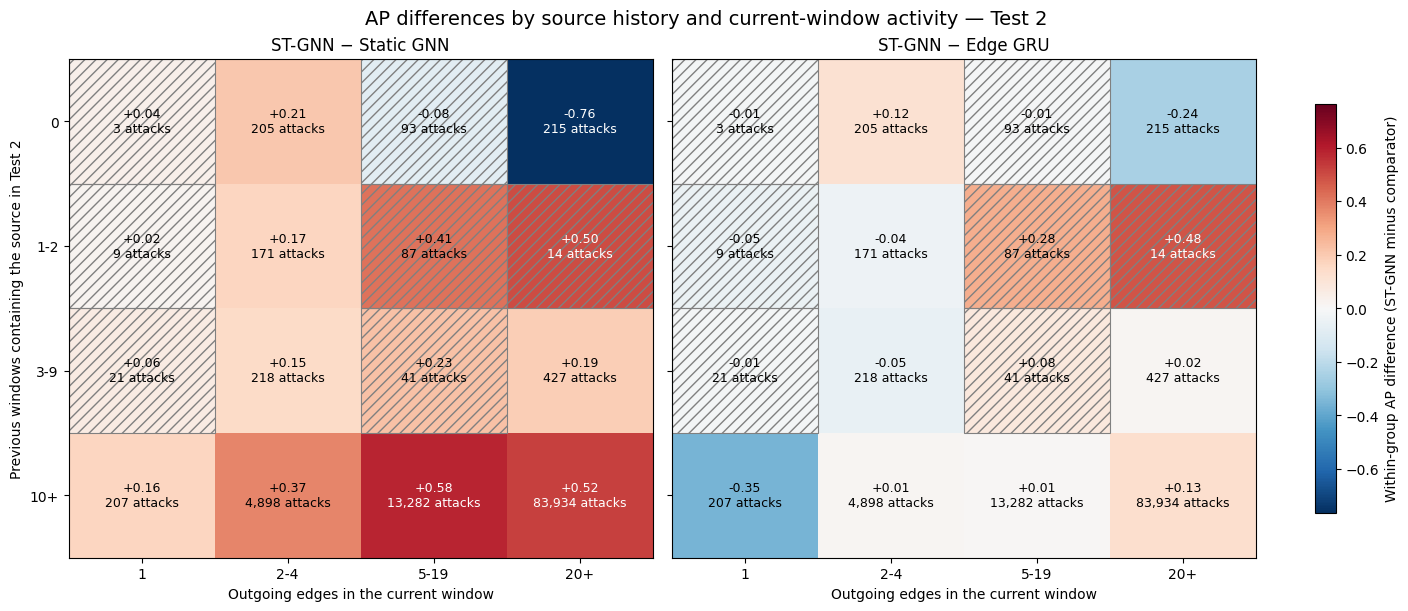

Hatched cells contain fewer than 100 attack-labeled flows.
Figure saved to: /content/drive/MyDrive/nids-mitre/results_comparison/stgnn_gain_audit


In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

history_order = ['0', '1-2', '3-9', '10+']
degree_order = ['1', '2-4', '5-19', '20+']
low_support_cutoff = 100  # visual warning only; cells remain in the figure

# Select the 16 joint history × degree groups from the last table.
joint = grouped.loc[
    grouped['group'].astype(str).str.contains(' / ', regex=False)
].copy()

joint[['history_bin', 'degree_bin']] = joint['group'].astype(str).str.split(
    ' / ', n=1, expand=True
)

assert len(joint) == 16, f'Expected 16 joint groups, found {len(joint)}'
assert not joint.duplicated(['history_bin', 'degree_bin']).any()
assert set(joint['history_bin']) == set(history_order)
assert set(joint['degree_bin']) == set(degree_order)

def as_grid(column):
    return (
        joint.pivot(
            index='history_bin',
            columns='degree_bin',
            values=column,
        )
        .reindex(index=history_order, columns=degree_order)
        .to_numpy(dtype=float)
    )

attack_counts = as_grid('attacks')
st_ap = as_grid('ST-GNN_AP')

comparators = [
    ('Static GNN', st_ap - as_grid('Static GNN_AP')),
    ('Edge GRU', st_ap - as_grid('Edge GRU_AP')),
]

# Both panels use the same color scale, centered on zero.
all_differences = np.stack([difference for _, difference in comparators])
color_limit = max(float(np.nanmax(np.abs(all_differences))), 1e-6)
norm = TwoSlopeNorm(
    vmin=-color_limit,
    vcenter=0,
    vmax=color_limit,
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6), sharex=True, sharey=True,
    constrained_layout=True,
)

for ax, (comparator, difference) in zip(axes, comparators):
    image = ax.imshow(
        difference,
        cmap='RdBu_r',
        norm=norm,
        aspect='auto',
    )

    ax.set_title(f'ST-GNN − {comparator}')
    ax.set_xticks(range(len(degree_order)), degree_order)
    ax.set_yticks(range(len(history_order)), history_order)
    ax.set_xlabel('Outgoing edges in the current window')

    for row in range(len(history_order)):
        for col in range(len(degree_order)):
            value = difference[row, col]
            attacks = int(attack_counts[row, col])

            if np.isfinite(value):
                text_color = (
                    'white' if abs(value) > 0.55 * color_limit else 'black'
                )
                label = f'{value:+.2f}\n{attacks:,} attacks'
            else:
                text_color = 'black'
                label = f'AP undefined\n{attacks:,} attacks'

            ax.text(
                col, row, label,
                ha='center', va='center',
                fontsize=9, color=text_color,
            )

            if attacks < low_support_cutoff:
                ax.add_patch(Rectangle(
                    (col - 0.5, row - 0.5), 1, 1,
                    fill=False, hatch='///',
                    edgecolor='gray', linewidth=0.8,
                ))

axes[0].set_ylabel('Previous windows containing the source in Test 2')

fig.colorbar(
    image, ax=axes, shrink=0.82,
    label='Within-group AP difference (ST-GNN minus comparator)',
)
fig.suptitle(
    'AP differences by source history and current-window activity — Test 2',
    fontsize=14,
)

plot_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit'
plot_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_dir / 'ap_history_degree_test2.png',
            dpi=300, bbox_inches='tight')
fig.savefig(plot_dir / 'ap_history_degree_test2.pdf',
            bbox_inches='tight')
plt.show()

print('Hatched cells contain fewer than 100 attack-labeled flows.')
print('Figure saved to:', plot_dir)

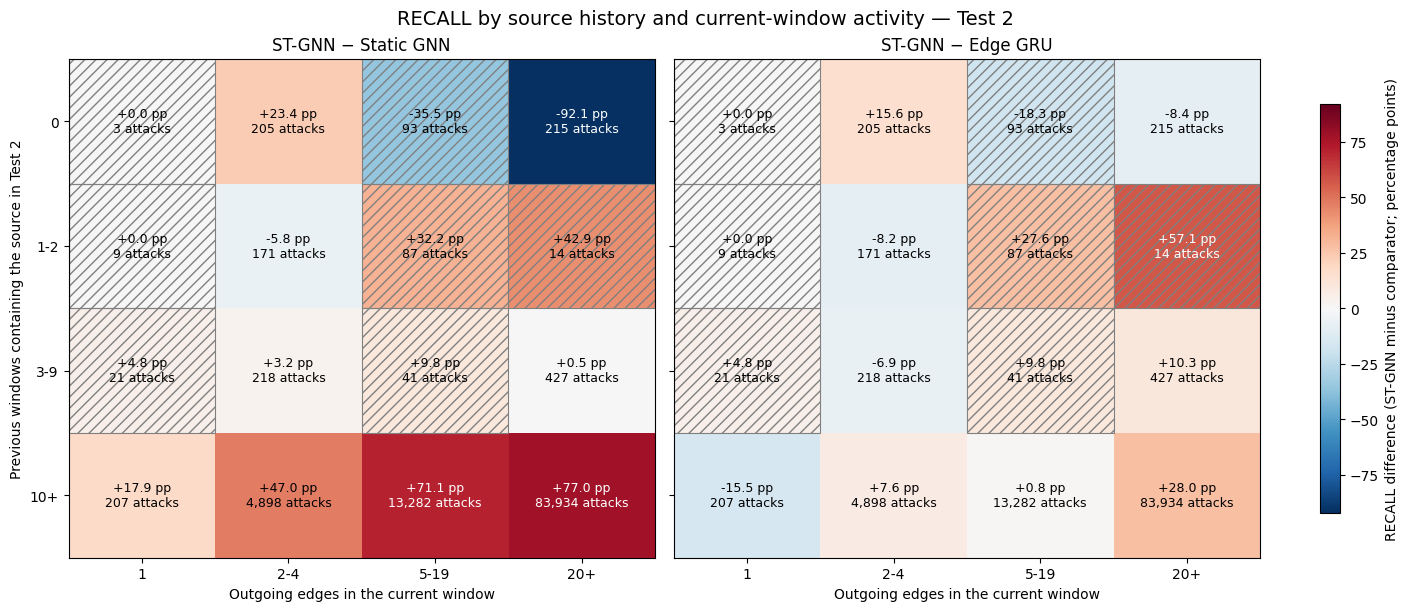

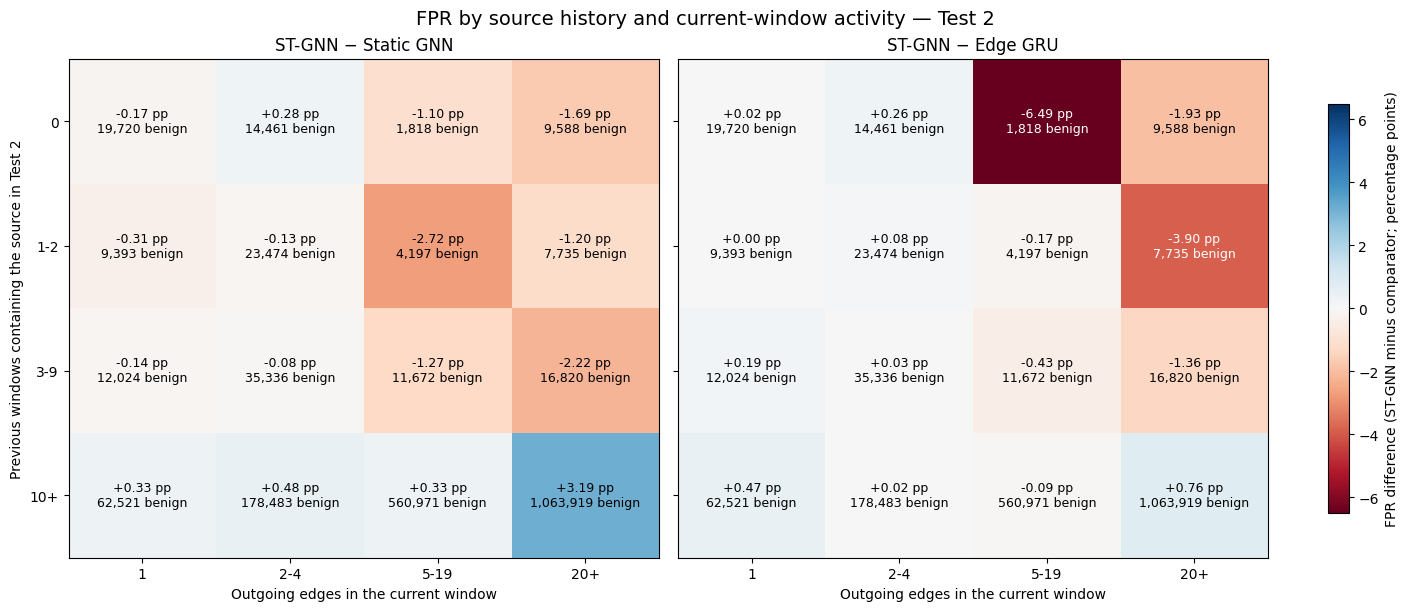

Figures saved to: /content/drive/MyDrive/nids-mitre/results_comparison/stgnn_gain_audit
Hatching marks cells with fewer than 100 flows in the relevant denominator.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

history_order = ['0', '1-2', '3-9', '10+']
degree_order = ['1', '2-4', '5-19', '20+']

# Keep only the 16 history × degree groups.
joint = grouped.loc[
    grouped['group'].astype(str).str.contains(' / ', regex=False)
].copy()
joint[['history_bin', 'degree_bin']] = joint['group'].astype(str).str.split(
    ' / ', n=1, expand=True
)

assert len(joint) == 16
assert not joint.duplicated(['history_bin', 'degree_bin']).any()

def as_grid(column):
    return (
        joint.pivot(
            index='history_bin',
            columns='degree_bin',
            values=column,
        )
        .reindex(index=history_order, columns=degree_order)
        .to_numpy(dtype=float)
    )

plot_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit'
plot_dir.mkdir(parents=True, exist_ok=True)

def plot_metric_differences(metric, denominator, denominator_label,
                            decimals, filename):
    # Convert rate differences to percentage points.
    differences = [
        ('Static GNN', 100 * (
            as_grid(f'ST-GNN_{metric}') -
            as_grid(f'Static GNN_{metric}')
        )),
        ('Edge GRU', 100 * (
            as_grid(f'ST-GNN_{metric}') -
            as_grid(f'Edge GRU_{metric}')
        )),
    ]
    counts = as_grid(denominator)
    all_values = np.stack([values for _, values in differences])
    color_limit = max(float(np.nanmax(np.abs(all_values))), 1e-6)

    # For recall, positive favors ST-GNN. For FPR, negative favors ST-GNN.
    cmap = 'RdBu_r' if metric == 'recall' else 'RdBu'
    norm = TwoSlopeNorm(
        vmin=-color_limit, vcenter=0, vmax=color_limit
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 6),
        sharex=True, sharey=True,
        constrained_layout=True,
    )

    for ax, (comparator, values) in zip(axes, differences):
        image = ax.imshow(
            values, cmap=cmap, norm=norm, aspect='auto'
        )
        ax.set_title(f'ST-GNN − {comparator}')
        ax.set_xticks(range(4), degree_order)
        ax.set_yticks(range(4), history_order)
        ax.set_xlabel('Outgoing edges in the current window')

        for row in range(4):
            for col in range(4):
                value = values[row, col]
                n = int(counts[row, col])
                color = (
                    'white'
                    if np.isfinite(value) and abs(value) > 0.55 * color_limit
                    else 'black'
                )
                value_text = (
                    f'{value:+.{decimals}f} pp'
                    if np.isfinite(value) else 'undefined'
                )
                ax.text(
                    col, row,
                    f'{value_text}\n{n:,} {denominator_label}',
                    ha='center', va='center',
                    fontsize=9, color=color,
                )

                # Small denominators are visually flagged, not excluded.
                if n < 100:
                    ax.add_patch(Rectangle(
                        (col - 0.5, row - 0.5), 1, 1,
                        fill=False, hatch='///',
                        edgecolor='gray', linewidth=0.8,
                    ))

    axes[0].set_ylabel(
        'Previous windows containing the source in Test 2'
    )
    fig.colorbar(
        image, ax=axes, shrink=0.82,
        label=f'{metric.upper()} difference '
              '(ST-GNN minus comparator; percentage points)',
    )
    fig.suptitle(
        f'{metric.upper()} by source history and current-window activity'
        ' — Test 2',
        fontsize=14,
    )

    fig.savefig(plot_dir / f'{filename}.png',
                dpi=300, bbox_inches='tight')
    fig.savefig(plot_dir / f'{filename}.pdf',
                bbox_inches='tight')
    plt.show()

# Recall denominator: attack-labeled flows in each cell.
plot_metric_differences(
    metric='recall',
    denominator='attacks',
    denominator_label='attacks',
    decimals=1,
    filename='recall_history_degree_test2',
)

# FPR denominator: benign-labeled flows in each cell.
plot_metric_differences(
    metric='FPR',
    denominator='benign',
    denominator_label='benign',
    decimals=2,
    filename='fpr_history_degree_test2',
)

print('Figures saved to:', plot_dir)
print('Hatching marks cells with fewer than 100 flows in the relevant denominator.')



## 3. Interpretation and record

If resetting memory reduces AP, this checkpoint **uses** historical state; it does not show that a retrained temporal architecture would outperform a non-temporal one. A gain over Static GNN among previously seen sources supports a historical-context hypothesis; a gain limited to high-degree sources supports an instantaneous-activity hypothesis. Check source concentration before attributing a pattern from one or two hosts to an entire campaign. A causal claim would require retraining variants without memory and without spatial message passing under the same seeds, data, and validation-selection protocol. These comparisons are diagnostic.


In [5]:
out_dir = DRIVE_ROOT / 'results_comparison' / 'stgnn_gain_audit'
out_dir.mkdir(parents=True, exist_ok=True)
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
summary.to_csv(out_dir / f'summary_{stamp}.csv', index=False)
pairs.to_csv(out_dir / f'paired_{stamp}.csv', index=False)
grouped.to_csv(out_dir / f'groups_{stamp}.csv', index=False)
manifest = {
    'code_commit': EXPECTED_COMMIT,
    'graph_root': str(GRAPH_ROOT / 'test2'),
    'original_labels': True,
    'threshold_operator': '>',
    'intervention': 'reset ST-GNN node memory before every nonempty graph window; no retraining',
    'runs': {name: {k: str(a[k]) for k in ('experiment','seed','run_id','checkpoint','threshold')}
             for name, a in ARTIFACTS.items()},
}
(out_dir / f'manifest_{stamp}.json').write_text(json.dumps(manifest, indent=2))
print('Results:', out_dir, '| suffix:', stamp)


Results: /content/drive/MyDrive/nids-mitre/results_comparison/stgnn_gain_audit | suffix: 20261020T192542Z
